# Kaggle Competition
Due Nov 11

Team 27: Rachel Liu, Henry Lam, Yang Xiao

The PR should include
* implementation,
* experimental code,
* README,
* dependencies, and
* instructions for generating your Kaggle predictions.

Your PR should preserve meaningful development history, including experiments, debugging, and changes to your approach

## Option 1: Neural Net
0. preprocess
1. pick a **model class**, 
2. an **estimation principle**
3. turn it into a **loss**,
4. **optimize** it, 
5. then **predict and evaluate** 

In [1]:
%matplotlib inline
import hashlib
import json
import re
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

import torch
from torch import nn

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, log_loss, roc_auc_score
from scipy.sparse import hstack, csr_matrix

SEED = 27   # team number, so every run uses the same split and weight initialization
np.random.seed(SEED)
torch.manual_seed(SEED)

### Step 0: Preprocess Data
Make the raw data (attributes) usable via featurization, PCA.

#### (a) Load the data

In [2]:
train_df = pd.read_csv("data/train.csv")   # id, text, label (1 = AI, 0 = human)
test_df = pd.read_csv("data/test.csv")     # id, text (no labels, this is what we submit predictions for)

print("train.csv shape:", train_df.shape)
print("test.csv  shape:", test_df.shape)
print("fraction labeled AI:", train_df["label"].mean())   # 0.5 means the classes are balanced
train_df.head()

train.csv shape: (10000, 3)
test.csv  shape: (3000, 2)
fraction labeled AI: 0.5


,id,text,label
0,1,Cipriani S.A. is an Italian hotel and leisure ...,0
1,2,My Grandpa passed away 3 years ago from cancer...,0
2,3,"""Petit Beurre -- Butter Cookies\n\n1 cup (2 st...",1
3,4,"In an unprecedented move, a dedicated gamer ha...",1
4,5,Chile's copper industry has registered record ...,0


#### (b) Split the training data
1. Fit on the training set, 
2. use the held-out development set to compare models,
3. pick hyperparameters, and
4. decide when to stop training.

Since the test set has no labels the held-out dev set will be used to compare models.

In [3]:
train_set, dev_set = train_test_split(
    train_df, test_size=0.2, random_state=SEED, stratify=train_df["label"]
)

y_train = train_set["label"].values
y_dev = dev_set["label"].values

print("training set size:   ", len(train_set), f"({y_train.mean()*100}% AI)")
print("development set size:", len(dev_set), f"({y_dev.mean()*100}% AI)")

training set size:    8000 (50.0% AI)
development set size: 2000 (50.0% AI)


#### (c) Prepare text and style features
* Keep punctuation, capitalization, and the original text available for style features. 
* Whitespace-normalized copies are used for TF-IDF
* A separate feature extractor measures repetition, sentence/paragraph regularity, punctuation, and phrase patterns that I felt were indications of AI.
* NEW: it also records exact-token profanity counts and a per-100-word rate as a weak style signal; it does not assume that profanity identifies human writing.

In [4]:
def clean_text(text):
    # Collapse runs of spaces/newlines into a single space
    return re.sub(r"\s+", " ", text).strip()

# NEW: a small, transparent profanity lexicon for a candidate style feature.
# This is a weak signal, not a rule: people and language models can both use profanity.
SWEAR_WORDS = {
    "ass", "asses", "asshole", "assholes", "bastard", "bastards", "bitch", "bitches",
    "bullshit", "cock", "cocks", "crap", "crappy", "cunt", "cunts", "dammit", "damn",
    "damned", "dick", "dicks", "dickhead", "dickheads", "fuck", "fucked", "fucker",
    "fuckers", "fucking", "fucks", "motherfucker", "motherfuckers", "motherfucking",
    "piss", "pissed", "pisses", "pissing", "prick", "pricks", "shit", "shits", "shitty",
    "shitting"
}

def extract_style_features(text):
    """Return measurable lexical, structural, repetition, and punctuation signals."""
    text = str(text)
    words = re.findall(r"\b[\w']+\b", text.lower())
    word_count = max(len(words), 1)
    # Match whole case-insensitive tokens; normalize the count by document length as well.
    swear_word_count = sum(word in SWEAR_WORDS for word in words)
    sentences = [s for s in re.split(r"(?<=[.!?])\s+|\n+", text.strip()) if s.strip()]
    paragraphs = [p for p in re.split(r"\n\s*\n", text.strip()) if p.strip()]
    sentence_lengths = [len(re.findall(r"\b[\w']+\b", s)) for s in sentences]
    paragraph_lengths = [len(re.findall(r"\b[\w']+\b", p)) for p in paragraphs]
    word_counts = pd.Series(words).value_counts()
    bigrams = list(zip(words, words[1:]))
    bigram_counts = pd.Series(bigrams).value_counts() if bigrams else pd.Series(dtype=int)
    normalized = text.lower()

    def repeat_fraction(counts, total):
        if total == 0 or len(counts) == 0:
            return 0.0
        return float((counts - 1).clip(lower=0).sum() / total)

    def mean(values):
        return float(np.mean(values)) if values else 0.0

    def std(values):
        return float(np.std(values)) if len(values) > 1 else 0.0

    # Candidate discourse templates; counts are normalized per 1,000 words below.
    template_patterns = {
        "not_just_but": r"\bnot just\b.{0,160}\bbut\b",
        "not_only_but_also": r"\bnot only\b.{0,160}\bbut also\b",
        "in_conclusion": r"\bin conclusion\b",
        "it_is_important_to_note": r"\bit is important to note\b",
        "moreover": r"\bmoreover\b",
        "furthermore": r"\bfurthermore\b",
    }
    features = {
        "log_word_count": np.log1p(len(words)),  # Log-scaled number of words.
        "log_character_count": np.log1p(len(text)),  # Log-scaled number of characters, including whitespace.
        "mean_word_length": mean([len(w) for w in words]),  # Average characters per token.
        "word_length_std": std([len(w) for w in words]),  # Variation in token lengths.
        "type_token_ratio": len(set(words)) / word_count,  # Unique words divided by total words; rough lexical diversity.
        "repeated_word_fraction": repeat_fraction(word_counts, len(words)),  # Fraction of word tokens beyond each word's first occurrence.
        "repeated_bigram_fraction": repeat_fraction(bigram_counts, len(bigrams)),  # Fraction of adjacent word-pairs beyond each pair's first occurrence.
        "sentence_count": np.log1p(len(sentences)),  # Log-scaled count of sentence-like spans.
        "mean_sentence_length": mean(sentence_lengths),  # Average words per sentence-like span.
        "sentence_length_std": std(sentence_lengths),  # Spread of sentence lengths.
        "sentence_length_cv": std(sentence_lengths) / max(mean(sentence_lengths), 1.0),  # Sentence-length spread relative to its mean.
        "paragraph_count": np.log1p(len(paragraphs)),  # Log-scaled count of blocks separated by blank lines.
        "mean_paragraph_length": mean(paragraph_lengths),  # Average words per paragraph block.
        "paragraph_length_std": std(paragraph_lengths),  # Spread of paragraph word counts.
        "repeated_sentence_fraction": (len(sentences) - len(set(s.strip().lower() for s in sentences))) / max(len(sentences), 1),  # Share of sentence-like spans duplicated after lowercasing.
        "exclamation_per_100_words": 100 * text.count("!") / word_count,  # Exclamation marks per 100 words.
        "question_per_100_words": 100 * text.count("?") / word_count,  # Question marks per 100 words.
        "comma_per_100_words": 100 * text.count(",") / word_count,  # Commas per 100 words.
        "semicolon_per_100_words": 100 * text.count(";") / word_count,  # Semicolons per 100 words.
        "colon_per_100_words": 100 * text.count(":") / word_count,  # Colons per 100 words.
        "dash_per_100_words": 100 * (text.count("—") + text.count("–")) / word_count,  # Em/en dashes per 100 words.
        "ellipsis_per_100_words": 100 * (text.count("...") + text.count("…")) / word_count,  # Three-dot or single-character ellipses per 100 words.
        "digit_character_fraction": sum(ch.isdigit() for ch in text) / max(len(text), 1),  # Fraction of all characters that are digits.
        "uppercase_character_fraction": sum(ch.isupper() for ch in text) / max(sum(ch.isalpha() for ch in text), 1),  # Fraction of letters that are uppercase.
        "contraction_per_100_words": 100 * len(re.findall(r"\b\w+['’](?:t|re|ve|ll|d|m)\b", normalized)) / word_count,  # Common English contractions per 100 words.
        "swear_word_count": swear_word_count,  # Exact-token count from the small lexicon above.
        "swear_words_per_100_words": 100 * swear_word_count / word_count,  # Length-normalized profanity rate.
    }
    for name, pattern in template_patterns.items():
        # Frequency of each hypothesized phrase pattern per 1,000 words.
        features[f"template_{name}_per_1000_words"] = 1000 * len(re.findall(pattern, normalized, flags=re.DOTALL)) / word_count
    return features

train_text = train_set["text"].map(clean_text)
dev_text = dev_set["text"].map(clean_text)
# Extract from untouched text so paragraph breaks and punctuation remain measurable.
train_style_raw = pd.DataFrame([extract_style_features(text) for text in train_set["text"]])
dev_style_raw = pd.DataFrame([extract_style_features(text) for text in dev_set["text"]])
style_scaler = StandardScaler()
train_style = style_scaler.fit_transform(train_style_raw)
dev_style = style_scaler.transform(dev_style_raw)

print(train_text.iloc[0][:400])

An $N$-level quantum system is coupled to a bosonic heat reservoir at positive temperature. We analyze the system-reservoir dynamics in the following regime: The strength $\lambda$ of the system-reservoir coupling is fixed and small, but larger than the spacing $\sigma$ of system energy levels. For vanishing $\sigma$ there is a manifold of invariant system-reservoir states and for $\sigma>0$ the o


#### (d) Featurize: word/character TF-IDF, style signals, and frozen-LM signals
* word vectorizer to look at **what** is said (vocabulary, common phrases), and also a 
* character vectorizer to look at **how** it is said (punctuation habits, spelling, word endings).
* in addition, after team discussion we appended a bunch other stuff for this new model, including
    * standardized numeric features for vocabulary diversity, 
    * repeated words/phrases, 
    * sentence and paragraph length patterns,
    * punctuation, 
    * contractions, and 
    * specific template features
* NEW in this version: append 23 label-free features from the frozen GPT-2 extractor, including token log-probability, entropy, rank, and sequence-drift summaries.

As always, the scaler and vectorizers are fit on training rows only, then reused for dev. Before running this section, generate the frozen features from the `submissions/team_27` directory with `python frozen_lm_features.py --download --data data` (once per cache), then `python frozen_lm_features.py --data data --output lm_features/gpt2 --batch-size 8`.

In [5]:
# NEW: frozen-language-model (LM) feature loading and validation.
# These 23 numeric signals were computed by frozen_lm_features.py without labels or fine-tuning.
# The source text files must be the same ones used for extraction; metadata hashes catch stale features.
LM_FEATURE_DIR = Path("lm_features/gpt2")

def load_lm_features(filename, frame):
    """Load one LM feature table, verify it matches the CSV, and return rows in frame ID order."""
    feature_path = LM_FEATURE_DIR / filename
    metadata_path = LM_FEATURE_DIR / (filename + ".json")
    if not feature_path.is_file() or not metadata_path.is_file():
        raise FileNotFoundError(
            f"Missing frozen-LM features for {filename}. Run frozen_lm_features.py first; "
            "see the featurization instructions above."
        )

    feature_df = pd.read_csv(feature_path)
    metadata = json.loads(metadata_path.read_text())
    input_path = Path("data") / filename
    input_hash = hashlib.sha256(input_path.read_bytes()).hexdigest()
    if metadata.get("model") != "openai-community/gpt2":
        raise ValueError(f"Unexpected frozen LM in {metadata_path}: {metadata.get('model')!r}")
    if metadata.get("input_sha256") != input_hash:
        raise ValueError(f"Stale LM features: {feature_path} was extracted from a different {input_path}.")
    if "id" not in feature_df or feature_df["id"].duplicated().any():
        raise ValueError(f"LM feature table must contain unique IDs: {feature_path}")
    if frame["id"].duplicated().any() or set(feature_df["id"]) != set(frame["id"]):
        raise ValueError(f"LM feature IDs do not match {input_path}.")
    feature_columns = [column for column in feature_df.columns if column != "id"]
    if metadata.get("features") != feature_columns:
        raise ValueError(f"LM feature columns do not match metadata: {feature_path}")
    # Align explicitly by ID so feature-file ordering can never silently mislabel examples.
    aligned = feature_df.set_index("id").loc[frame["id"], feature_columns]
    values = aligned.to_numpy(dtype=np.float64)
    if not np.isfinite(values).all():
        raise ValueError(f"Non-finite LM feature value found in {feature_path}.")
    return pd.DataFrame(values, index=frame["id"].to_numpy(), columns=feature_columns)

# Load whole-file tables once, then select the existing train/dev split by ID.
# This keeps the previously fixed seed-27 split unchanged.
lm_train_by_id = load_lm_features("train.csv", train_df)
lm_test_by_id = load_lm_features("test.csv", test_df)
train_lm_raw = lm_train_by_id.loc[train_set["id"]].to_numpy()
dev_lm_raw = lm_train_by_id.loc[dev_set["id"]].to_numpy()

# NEW: fit the LM scaler on the training partition only to prevent dev-data leakage.
lm_scaler = StandardScaler()
train_lm = lm_scaler.fit_transform(train_lm_raw)
dev_lm = lm_scaler.transform(dev_lm_raw)
print("frozen-LM features:", train_lm.shape[1])

word_vectorizer = TfidfVectorizer(
    lowercase=True, ngram_range=(1, 2), min_df=3, max_features=20000, sublinear_tf=True
)
char_vectorizer = TfidfVectorizer(
    lowercase=False, analyzer="char_wb", ngram_range=(3, 5), min_df=5, max_features=30000, sublinear_tf=True
)

# Add the dense numeric style and LM blocks as sparse matrices beside the TF-IDF blocks.
X_train = hstack([word_vectorizer.fit_transform(train_text),
                  char_vectorizer.fit_transform(train_text),
                  csr_matrix(train_style),
                  csr_matrix(train_lm)]).tocsr()
X_dev = hstack([word_vectorizer.transform(dev_text),
                char_vectorizer.transform(dev_text),
                csr_matrix(dev_style),
                csr_matrix(dev_lm)]).tocsr()

print("train matrix:", X_train.shape, "   dev matrix:", X_dev.shape)

frozen-LM features: 23
train matrix: (8000, 50056)    dev matrix: (2000, 50056)


#### (e) Wrap the data for PyTorch
The matrices are sparse which means they are mostly zeros. We only need to turn one **minibatch** of rows into a dense tensor at a time because converting the entire one would take a lot of memory. 

In [6]:
class SparseTextDataset(torch.utils.data.Dataset):
    def __init__(self, X, y=None):
        self.X = X   # scipy sparse matrix, shape (n, d)
        self.y = y   # numpy array of 0/1 labels, or None for the test set

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, i):
        return i   # just hand back row indices; collate() builds the batch

    def collate(self, idx):
        # Slice the rows for this batch and convert only those to a dense float tensor.
        xb = torch.tensor(self.X[idx].toarray(), dtype=torch.float32)
        if self.y is None:
            return xb
        yb = torch.tensor(self.y[idx], dtype=torch.float32)
        return xb, yb

def make_loader(X, y=None, batch_size=64, shuffle=False):
    ds = SparseTextDataset(X, y)
    return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=shuffle, collate_fn=ds.collate)

train_loader = make_loader(X_train, y_train, shuffle=True)   # reshuffle every epoch for SGD
dev_loader = make_loader(X_dev, y_dev)

xb, yb = next(iter(train_loader))
print("one batch:", xb.shape, yb.shape)

one batch: torch.Size([64, 50056]) torch.Size([64])


### Step 1: Parametrize
The model class is a **multilayer perceptron** (MLP) where each layer computes the **activation** of the weighted inputs plus bias, feeding forward per layer. 

In [7]:
# this defines a simple feedforward neural network with dropout and a choice of activation function.
class MLP(nn.Module):
    def __init__(self, sizes, activation="relu", dropout=0.5):
        super().__init__()
        self.sizes = sizes
        # one Linear layer per pair of consecutive sizes, W^[k] has shape (sizes[k], sizes[k-1])
        self.layers = nn.ModuleList([nn.Linear(m, n) for m, n in zip(sizes[:-1], sizes[1:])])
        self.g = nn.ReLU() if activation == "relu" else nn.Sigmoid()
        self.dropout = nn.Dropout(dropout)   # only active in model.train() mode

    def forward(self, x):
        for layer in self.layers[:-1]:
            x = self.dropout(self.g(layer(x)))   # A^[k] = g(W^[k] A^[k-1] + b^[k])
        # last layer: no activation, one logit per example; squeeze(-1) turns (batch, 1) into (batch,)
        return self.layers[-1](x).squeeze(-1)

SIZES = [X_train.shape[1], 256, 64, 1]
model = MLP(SIZES)
print(model)
print("number of parameters:", sum(p.numel() for p in model.parameters()))

MLP(
  (layers): ModuleList(
    (0): Linear(in_features=50056, out_features=256, bias=True)
    (1): Linear(in_features=256, out_features=64, bias=True)
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
  (g): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
)
number of parameters: 12831105


### Step 2: Choose Estimation Principle
We will use **Maximum likelihood / logistic regression**. We model each label as a
Bernoulli RV whose probability comes from the network and choose theta to make observed training labels as likely as possible which is the process of .

We also add **L2 penalty** to reduce overfitting

### Step 3: Define a Loss/Objective Function
Maximizing the log-likelihood = minimizing its negative, which is the **binary cross-entropy** loss. 
* Pass raw model logits and 0/1 labels; this loss applies sigmoid internally and
* computes the mean binary cross-entropy for the batch.

In [8]:
loss_fn = nn.BCEWithLogitsLoss()

### Step 4: Optimize
#### (a) Backpropagation via PyTorch
PyTorch's `loss.backward()` derives the gradient with cross entropy and sigmoid output. It flows backwards by applying the weighted deltas to the layers below it. 
We also decided to use Adam which converges faster that SGD. 

In [9]:
# this checks how the model performs on a dataset (the dev set) and returns the average loss and predicted probabilities
# does not update the model  
def evaluate(model, loader):
    # Average loss and predicted probabilities over a whole dataset, without updating weights.
    model.eval()                       # turns dropout off
    losses, probs = [], []
    with torch.no_grad():              # no need to track gradients here
        for xb, yb in loader:
            logits = model(xb)
            losses.append(loss_fn(logits, yb).item() * len(yb))
            probs.append(torch.sigmoid(logits))
    return sum(losses) / len(loader.dataset), torch.cat(probs).numpy()

# this summarized the gradients for each layer and plots how strongly each layer should change to reduce loss
# norm gives one size for that layer's gradients
def layer_grad_norms(model):
    # ||(dW^[k], db^[k])|| for every layer k, like grad_layer1..3 in the lecture
    return [float(torch.sqrt(l.weight.grad.pow(2).sum() + l.bias.grad.pow(2).sum())) for l in model.layers]

# this trains the model for multiple epoch and calculates the loss w/ autograd
# also uses Adam to update the weights and then
# stores the weights so that the one with the lowest dev loss is used at the end
def train(model, train_loader, dev_loader=None, epochs=15, lr=1e-3, weight_decay=1e-5, verbose=True):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = []                       # one row per epoch, like the lecture's `rows`
    best_dev_loss, best_state = float("inf"), None
    L = len(model.layers)

    for epoch in range(1, epochs + 1):
        model.train()                  # turns dropout on
        total, grad_sum = 0.0, np.zeros(L)
        for xb, yb in train_loader:
            optimizer.zero_grad()      # clear gradients from the previous batch
            loss = loss_fn(model(xb), yb)   # forward pass + loss
            loss.backward()            # backpropagation: compute dJ/dtheta
            grad_sum += layer_grad_norms(model)
            optimizer.step()           # theta <- theta - lr * (adjusted) gradient
            total += loss.item() * len(yb)

        row = {"epoch": epoch, "train_loss": total / len(train_loader.dataset)}
        row.update({f"grad_layer{k+1}": g / len(train_loader) for k, g in enumerate(grad_sum)})
        row["weight_norm"] = float(torch.sqrt(sum(l.weight.detach().pow(2).sum() for l in model.layers)))

        msg = f"epoch {epoch:2d}   train loss {row['train_loss']:.4f}"
        if dev_loader is not None:
            dev_loss, p = evaluate(model, dev_loader)
            row["dev_loss"] = dev_loss
            row["dev_accuracy"] = accuracy_score(dev_loader.dataset.y, p >= 0.5)
            msg += f"   dev loss {dev_loss:.4f}   dev acc {row['dev_accuracy']:.4f}"
            # Early stopping: remember the best weights seen so far
            if dev_loss < best_dev_loss:
                best_dev_loss = dev_loss
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        history.append(row)
        if verbose:
            print(msg)

    if best_state is not None:
        model.load_state_dict(best_state)   # roll back to the best epoch
    return pd.DataFrame(history).set_index("epoch")

In [10]:
# here we tune our hyperparameters on the dev set
SIZES = [X_train.shape[1], 256, 64, 1]
ACTIVATION = "relu"
DROPOUT = 0.5
LR = 1e-4    
WEIGHT_DECAY = 1e-5
EPOCHS = 12

torch.manual_seed(SEED)
model = MLP(SIZES, ACTIVATION, DROPOUT)
history = train(model, train_loader, dev_loader, epochs=EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY)

best_epoch = int(history["dev_loss"].idxmin())
print("best epoch:", best_epoch)
history.round(4)

epoch  1   train loss 0.5921   dev loss 0.3862   dev acc 0.9365
epoch  2   train loss 0.2306   dev loss 0.1229   dev acc 0.9700
epoch  3   train loss 0.1004   dev loss 0.0798   dev acc 0.9775
epoch  4   train loss 0.0652   dev loss 0.0638   dev acc 0.9795
epoch  5   train loss 0.0474   dev loss 0.0565   dev acc 0.9815
epoch  6   train loss 0.0363   dev loss 0.0515   dev acc 0.9855
epoch  7   train loss 0.0269   dev loss 0.0484   dev acc 0.9845
epoch  8   train loss 0.0216   dev loss 0.0461   dev acc 0.9860
epoch  9   train loss 0.0166   dev loss 0.0455   dev acc 0.9865
epoch 10   train loss 0.0134   dev loss 0.0449   dev acc 0.9865
epoch 11   train loss 0.0107   dev loss 0.0439   dev acc 0.9870
epoch 12   train loss 0.0090   dev loss 0.0440   dev acc 0.9875
best epoch: 11


,train_loss,grad_layer1,grad_layer2,grad_layer3,weight_norm,dev_loss,dev_accuracy
epoch,,,,,,,
1,0.5921,0.2554,0.1146,0.1905,11.7732,0.3862,0.9365
2,0.2306,0.3514,0.1471,0.3119,16.1924,0.1229,0.9700
3,0.1004,0.3418,0.1050,0.1791,18.3870,0.0798,0.9775
4,0.0652,0.3067,0.0911,0.1399,19.9240,0.0638,0.9795
5,0.0474,0.2928,0.0783,0.1142,21.1859,0.0565,0.9815
6,0.0363,0.2600,0.0672,0.0958,22.2546,0.0515,0.9855
7,0.0269,0.2087,0.0548,0.0807,23.1556,0.0484,0.9845
8,0.0216,0.1990,0.0475,0.0673,23.9795,0.0461,0.9860
9,0.0166,0.1744,0.0404,0.0577,24.6506,0.0455,0.9865


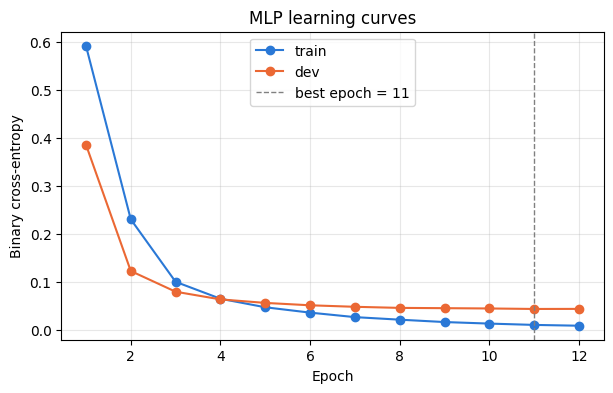

In [11]:
# here we plot the learning curves
# if we see that dev loss is going up while train loss is going down, that means we are overfitting
plt.figure(figsize=(7, 4))
plt.plot(history.index, history["train_loss"], marker="o", color="#2a78d6", label="train")
plt.plot(history.index, history["dev_loss"], marker="o", color="#eb6834", label="dev")
plt.axvline(best_epoch, color="gray", linestyle="--", linewidth=1, label=f"best epoch = {best_epoch}")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy")
plt.title("MLP learning curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

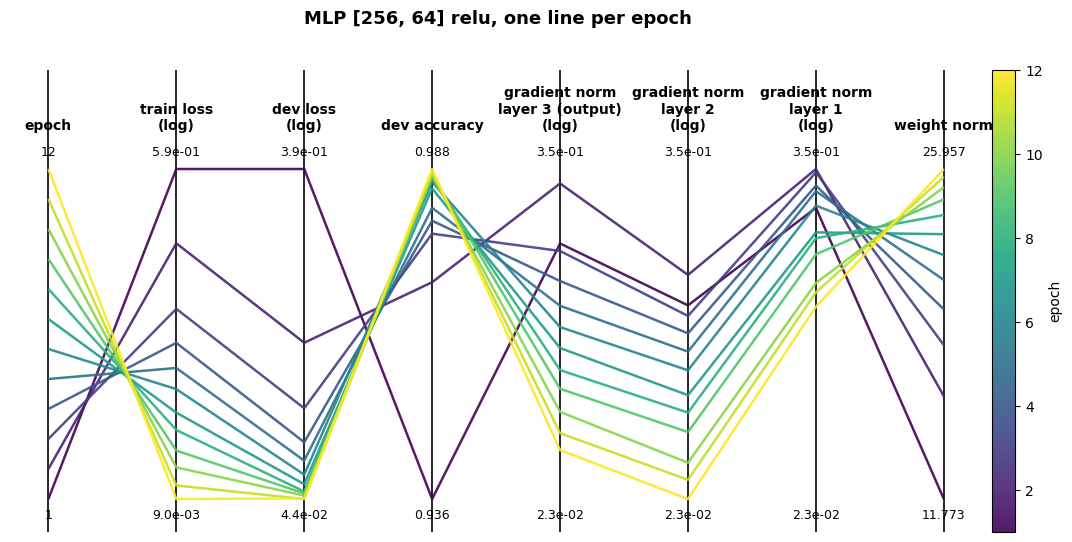

In [12]:
# parallel coordinates plot to see how the gradients change over time for each layer
# we did something similar in lecture 13, felt it was helpful to visualize
def parallel_coordinates(history, title):
    rows = history.reset_index()
    grad_cols = [c for c in rows.columns if c.startswith("grad_layer")]
    axes = ([("epoch", "epoch", False), ("train_loss", "train loss", True), ("dev_loss", "dev loss", True),
             ("dev_accuracy", "dev accuracy", False)]
            + [(c, f"gradient norm\nlayer {c[-1]}" + (" (output)" if c == grad_cols[-1] else ""), True)
               for c in reversed(grad_cols)]
            + [("weight_norm", "weight norm", False)])
    M = rows[[k for k, _, _ in axes]].to_numpy(dtype=float)
    V = np.column_stack([np.log10(np.maximum(M[:, j], 1e-12)) if lg else M[:, j] for j, (_, _, lg) in enumerate(axes)])
    GR = [j for j, (k, _, _) in enumerate(axes) if k.startswith("grad")]
    glo, ghi = V[:, GR].min(), V[:, GR].max()               # one scale for all gradient axes
    Z = np.zeros_like(V)
    for j in range(len(axes)):
        lo, hi = (glo, ghi) if j in GR else (V[:, j].min(), V[:, j].max())
        Z[:, j] = (V[:, j] - lo) / (hi - lo + 1e-12)

    fig, ax = plt.subplots(figsize=(13, 6))
    xs = np.arange(len(axes))
    lc = LineCollection([np.column_stack([xs, z]) for z in Z], array=M[:, 0], cmap="viridis",
                        linewidths=1.8, alpha=0.9)
    ax.add_collection(lc)
    for j, (key, label, lg) in enumerate(axes):
        ax.axvline(j, color="black", lw=1.2, zorder=0)
        lo, hi = (10 ** glo, 10 ** ghi) if j in GR else (M[:, j].min(), M[:, j].max())
        fmt = (lambda v: f"{v:.0f}") if key == "epoch" else (lambda v: f"{v:.1e}") if lg else (lambda v: f"{v:.3f}")
        ax.text(j, 1.03, fmt(hi), ha="center", va="bottom", fontsize=9)
        ax.text(j, -0.03, fmt(lo), ha="center", va="top", fontsize=9)
        ax.text(j, 1.11, label + ("\n(log)" if lg else ""), ha="center", va="bottom", fontsize=10, fontweight="bold")
    ax.set_xlim(-0.3, len(axes) - 0.7)
    ax.set_ylim(-0.1, 1.3)
    ax.axis("off")
    fig.colorbar(lc, ax=ax, fraction=0.025, pad=0.01).set_label("epoch")
    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.show()

parallel_coordinates(history, f"MLP {SIZES[1:-1]} {ACTIVATION}, one line per epoch")

### Step 5: Predict and Evaluate
#### (a) Evaluate on the dev set
The submission asks for a probability per text, so in addition to 
* accuracy and 
* F1 we also look at 
* log loss and
* ROC AUC. 
Unlike accuracy and F1, log loss and ROC AUC score the probabilities themselves rather than just the 0/1 binary decision.

In [13]:
def report(name, y_true, p):
    # p = predicted P(AI); threshold at 0.5 for the hard 0/1 metrics
    y_pred = (p >= 0.5).astype(int)
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "log loss": log_loss(y_true, p),
        "ROC AUC": roc_auc_score(y_true, p),
    }

_, p_train = evaluate(model, make_loader(X_train, y_train))
_, p_dev = evaluate(model, dev_loader)

results = pd.DataFrame([
    report("MLP (train)", y_train, p_train),
    report("MLP (dev)", y_dev, p_dev),
]).set_index("model")
results.round(4)

,accuracy,F1,log loss,ROC AUC
model,,,,
MLP (train),0.9992,0.9992,0.0055,1.0000
MLP (dev),0.9870,0.9869,0.0439,0.9981


In [14]:
# Look at the dev texts the model got most confidently wrong, to get ideas for better features.
dev_view = dev_set.assign(p_ai=p_dev)
wrong = dev_view[(dev_view["p_ai"] >= 0.5) != (dev_view["label"] == 1)]
wrong = wrong.reindex((wrong["p_ai"] - 0.5).abs().sort_values(ascending=False).index)
for _, row in wrong.head(10).iterrows():
    print(f"label={row['label']}   P(AI)={row['p_ai']:.3f}\n{row['text'][:300]}...\n")

label=1   P(AI)=0.001
Cynthia Alina Turner (born April 18, 1960 in San Rafael, Marin County, California1) is an American actress, producer, and model. She had a recurring role on Star Trek: Voyager as Kasidy Yates, a Starfleet flight controller and mother of Seven of Nine. From 1989 until 1990, Turner played the role of ...

label=1   P(AI)=0.005
Arie Lev Gruzman (Hebrew: אריה לב גרוזמן; born 1937) is a French mathematician. He is a professor at Institut Henri Poincaré, Paris, at the University of Paris at Vincennes, and at the Weizmann Institute. He has been director of the Laboratory of Stochastic Analysis and Mathematical Statistics in th...

label=1   P(AI)=0.005
Lorenzo D. Tañada (July 25, 1821–November 4, 1879) was a Filipino lawyer and a nationalist legislator representing the provinces of Ilocos Sur and Pangasinan in the Spanish Cortes Generales during the last years of the 19th century, making him the longest serving Filipino delegate to the Cortes and ...

label=0   P(AI)=0.9

#### (b) Retrain on all labeled data and predict the test set
Once hyperparameters are chosen, refit the vectorizers and the network on train + dev for the number of epochs that was best on dev (6).
There's no dev set left for early stopping, so `best_epoch` stands in for it.

In [15]:
# NEW: when refitting on all labeled rows, refit the LM scaler on all labeled LM features.
# The feature values themselves remain label-free; only this numeric scaling is fitted here.
full_lm_raw = lm_train_by_id.loc[train_df["id"]].to_numpy()
test_lm_raw = lm_test_by_id.loc[test_df["id"]].to_numpy()
full_lm = lm_scaler.fit_transform(full_lm_raw)
test_lm = lm_scaler.transform(test_lm_raw)

full_text = train_df["text"].map(clean_text)
y_full = train_df["label"].values
test_text = test_df["text"].map(clean_text)
full_style_raw = pd.DataFrame([extract_style_features(text) for text in train_df["text"]])
test_style_raw = pd.DataFrame([extract_style_features(text) for text in test_df["text"]])

# Refit feature transforms on all labeled rows, then transform test using the same fitted transforms.
full_style = style_scaler.fit_transform(full_style_raw)
test_style = style_scaler.transform(test_style_raw)
# Keep the final train/test feature order exactly the same as the train/dev matrices above.
X_full = hstack([word_vectorizer.fit_transform(full_text),
                 char_vectorizer.fit_transform(full_text),
                 csr_matrix(full_style),
                 csr_matrix(full_lm)]).tocsr()
X_test = hstack([word_vectorizer.transform(test_text),
                 char_vectorizer.transform(test_text),
                 csr_matrix(test_style),
                 csr_matrix(test_lm)]).tocsr()
print("full matrix:", X_full.shape, "   test matrix:", X_test.shape)

torch.manual_seed(SEED)
final_model = MLP([X_full.shape[1]] + SIZES[1:], ACTIVATION, DROPOUT)
training_start = time.perf_counter()
train(final_model, make_loader(X_full, y_full, shuffle=True), epochs=best_epoch, lr=LR, weight_decay=WEIGHT_DECAY)
training_runtime = time.perf_counter() - training_start
print(f"Neural-network training runtime: {training_runtime:.2f} seconds")

full matrix: (10000, 50056)    test matrix: (3000, 50056)
epoch  1   train loss 0.5417
epoch  2   train loss 0.1577
epoch  3   train loss 0.0781
epoch  4   train loss 0.0528
epoch  5   train loss 0.0391
epoch  6   train loss 0.0290
epoch  7   train loss 0.0213
epoch  8   train loss 0.0160
epoch  9   train loss 0.0120
epoch 10   train loss 0.0103
epoch 11   train loss 0.0077
Neural-network training runtime: 58.97 seconds


In [16]:
# Predict P(AI) for each test text. The test loader has no labels, so we don't use evaluate().
final_model.eval()
with torch.no_grad():
    p_test = torch.cat([torch.sigmoid(final_model(xb))
                        for xb in make_loader(X_test)]).numpy()

# Same format as sample_submission.csv: id, label (probability of AI)
submission = pd.DataFrame({"id": test_df["id"], "label": p_test})
submission.to_csv("submission_nn3.csv", index=False)
print(submission.shape)
submission.head()

(3000, 2)


,id,label
0,13001,0.999998
1,13002,0.000436
2,13003,0.056179
3,13004,0.000264
4,13005,0.999571
